In [1]:
#Bloque 1: Librerias Necesarias
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
import networkx as nx
import re

In [2]:
# Bloque 2: Creación de la superficie Triangulada 

def poligono_y_triangulacion(n,v):
    """
    Propósito:
        Construir la superficie triangulada deseada. Genera las estructuras de datos asociadas a las variables clúster de tipo An.

    Entrada:
        n (int): el álgebra es de tipo A_n (polígono de n+3 vértices).
        v (list): n pares de coordenadas ordenados (list de listas [a,b]); cada par es una curva.
            El orden en v es la numeración de las variables de conglomerado.

    Salida:
        fig, ax: gráfica de la superficie triangulada.
        variables_cluster (dict): asocia cada variable x_i con la curva v[i].
        triangulos (list): ternas que identifican los triángulos formados en el polígono.
    """
  # 1. Crear vértices de P_{n+3}
    num_vertices = n + 3
    #se piensa P_{n+3} como la distribucion regular de los vertices sobre una circunf de radio 1, escribimos las coord en polares
    angulos = np.linspace(0, 2 * np.pi, num_vertices, endpoint=False)
    x = np.cos(angulos) #vector que contiene todas las coordenadas x de cada uno de los vértices
    y = np.sin(angulos) #analogo con las coordenadas y

    #creamos el lienzo y el marco de dibujo
    fig, ax = plt.subplots(figsize=(6, 6))

    # Dibujar borde del polígono
    # Unimos el último vértice con el primero agregando x[0] e y[0] al final
    x_ciclo = np.append(x, x[0])
    y_ciclo = np.append(y, y[0])
    ax.plot(x_ciclo, y_ciclo, 'k-', lw=2, label="Polígono") #dibuja las líneas continuas del borde exterior del polígono.

    # Etiquetar vértices
    for i in range(num_vertices):
        ax.text(x[i]*1.1, y[i]*1.1, f"v_{i}", fontsize=12, ha='center')

    triangulos=[]

    # 1. Crear el conjunto de TODAS las aristas (diagonales + bordes del polígono)
    aristas = set()

    # 1ero añadimos las diagonales internas de 'v'
    for d in v:
        u, w = min(d), max(d)
        aristas.add((u, w))

    # Añadimos los bordes del polígono (del 0 al n_vertices - 1)
    for i in range(num_vertices):
        u, w = i, (i + 1) % num_vertices
        aristas.add((min(u, w), max(u, w)))

    # 2. Generar todos los triángulos válidos combinando 3 vértices
    triangulos = []
    from itertools import combinations

    for a, b, c in combinations(range(num_vertices), 3):
        # Si los 3 lados existen en nuestro conjunto de aristas, es un triángulo
        if (a, b) in aristas and (b, c) in aristas and (a, c) in aristas:
            triangulos.append([a, b, c]) #la cant debe ser n+1

    assert len(triangulos) == n + 1, "v no es una triangulación válida" 

    # 1. Almacenar y etiquetar las variables cluster (diagonales de la triangulación)
    variables_cluster = []

    for i in range(len(v)):
        # Guardar como tupla de vértices
        v_origen = v[i][0]
        v_destino = v[i][1]
        x_var = f"x_{i}"  # Nombre de la variable cluster
        variables_cluster.append(
            {"nombre": x_var, "arco": [v_origen, v_destino]}
        )

        # Dibujar diagonal
        ax.plot(
                [x[v_origen], x[v_destino]],
                [y[v_origen], y[v_destino]],
                "b--",
                alpha=0.6,
            )

        # Colocar texto de la variable cluster en el punto medio del arco
        x_medio = (x[v_origen] + x[v_destino]) / 2
        y_medio = (y[v_origen] + y[v_destino]) / 2
        ax.text(
            x_medio,
            y_medio,
            x_var,
            color="blue",
            fontsize=10,
            weight="bold",
            bbox=dict(
                boxstyle="round,pad=0.2", fc="white", ec="blue", alpha=0.7
            ),
        )
    ax.set_aspect("equal")
    ax.axis("off")
    return fig, ax, variables_cluster, triangulos

In [3]:
#Bloque 3: Ingreso de la curva que corta la superficie e identificación de las variables intersecadas

#La función utiliza la definida anteriormente, en el Bloque 2. 

def trazo_curva(n,v,c):
    """
    Propósito:
        Construir la superficie triangulada junto con una curva orientada que la atraviesa, y determinar qué curvas 
        de la triangulación son cortadas por ella, en el orden en que lo hace, junto con sus variables de conglomerado asociadas.

    Entrada:
        n (int): el álgebra es de tipo A_n (polígono de n+3 vértices).
        v (list): n pares de coordenadas ordenados (list de listas [a,b]); cada par es una curva.
            El orden en v es la numeración de las variables de conglomerado.
        c (list): es una lista [c1,c2] que representa la curva orientada de c1 a c2 la cual corta la superficie triangulada.

    Salida:
        fig, ax: gráfica de la superficie triangulada con la curva c. 
        intersecciones_ordenadas (list): list de listas de pares con las curvas de la triangulación que son intersecadas por c, en el orden
        que son atravesadas.
        variables_filtradas (dict): describe las variables de conglomerado que corresponden a las curvas intersecadas, en el mismo orden. 
        cluster_vars (dict): asocia cada variable x_i con la curva v[i] (mismo dato que Bloque 2)
        triang (list): ternas que identifican los triángulos formados en el polígono (la misma que devuelve el Bloque 2).
    """
    N = n + 3
    #se piensa P_{n+3} como la distribucion regular de los vertices sobre una circunf de radio 1, escribimos las coord en polares
    angulos = np.linspace(0, 2 * np.pi, N, endpoint=False)
    x = np.cos(angulos) #vector que contiene todas las coordenadas x de cada uno de los vértices
    y = np.sin(angulos) #analogo con las coordenadas y
    # Dibujar la curva gamma (ejemplo: de vértice 1 a endpoint_curva)
    fig, ax, cluster_vars, triang = poligono_y_triangulacion(n,v)
    ax.plot([x[c[0]], x[c[1]]], [y[c[0]], y[c[1]]], 'r-', lw=2.5, label="Curva γ")
    
    c1, c2 = c                      # orientación: se recorre de c1 a c2
    L = (c2 - c1) % N               # posición de c2 respecto a c1
    
    def pos(x):
        return (x - c1) % N         # c1 -> 0, c2 -> L
    
    intersecciones = []
    for i, d in enumerate(v):
        x, y = d
    
        # 1. Ignorar si comparten extremos con c
        if len({c1, c2, x, y}) < 4:
            continue
    
        px, py = pos(x), pos(y)
    
        # 2. Cruce: un extremo en el arco (0, L) y el otro en (L, N)
        x_dentro = 0 < px < L
        y_dentro = 0 < py < L
        if x_dentro == y_dentro:
            continue                # ambos del mismo lado -> no cruza
    
        p_in, p_out = (px, py) if x_dentro else (py, px)
    
        # 3. Posición a lo largo de c1 -> c2:
        #    p_in sube de 0 a L, p_out baja de N a L
        m = p_in + (N - p_out)
        intersecciones.append((m, i, d))
    
        # 4. Ordenar según el recorrido de c1 a c2
        intersecciones.sort(key=lambda item: item[0])
        intersecciones_ordenadas = [d for _, _, d in intersecciones]
        
        # 5. Filtrar y reordenar cluster_vars
        arco_a_var = {frozenset(dic["arco"]): dic for dic in cluster_vars}
        variables_filtradas = [
            arco_a_var[frozenset(par)]
            for par in intersecciones_ordenadas
            if frozenset(par) in arco_a_var
        ]
    return fig, ax, intersecciones_ordenadas, variables_filtradas, cluster_vars, triang

In [4]:
#Bloque 4: Dibujo del grafo de serpiente y descripción de sus tiles

#El bloque 3 se incorpora a esta nueva función

def grafo_serpiente2(n,v,c):
    """
    Propósito:
        Construir y dibujar el grafo de serpiente G_c asociado a la superficie triangulada y a la curva c. Describir sus tiles,
        indicando qué vértice del polígono corresponde a cada vértice de cada tile.

    Entrada (mismos datos del Bloque 3):
        n (int): el álgebra es de tipo A_n (polígono de n+3 vértices).
        v (list): lista de n listas [a, b]; cada una es una curva de la triangulación. 
        El orden en v es la numeración de las variables de conglomerado.
        c (list): lista [c1, c2] que representa la curva orientada de c1 a c2 que corta la superficie triangulada.

    Salida:
        Gráfica de la superficie triangulada con la curva c y el grafo de serpiente G_c.
        G (networkx.Graph): grafo de serpiente G_c. Sus vértices y aristas son los de cada tile.
        tiles_orientadas (list de dict): una entrada por tile, en el orden en que c las atraviesa. Cada diccionario asocia 
        cada vértice de la tile con el vértice del polígono que le corresponde (un valor entre 0 y n+2).
        variables_filtradas (dict): describe las variables de conglomerado que corresponden a las curvas intersecadas, en el mismo orden. 
        variables_cluster (dict): todas las variables asociadas a la triangulación.
    """
    fig, ax, intersecciones, variables_filtradas, variables_cluster, triangulacion = trazo_curva(n,v,c)
    #intersecciones: Lista de aristas cortadas [[u,v], ...], variables_cluster: [{'nombre': 'x_1', 'arco': [1, 4]}, ...]

    # 1. Crear un diccionario de consulta rápida: frozenset({u, v}) -> 'x_i'
    mapa_variables = {
        frozenset(d["arco"]): d["nombre"] for d in variables_cluster
    }

    def obtener_variable(u, v):
        """Busca el nombre de la variable para el arco (u,v).

        Devuelve vacio o el par si no es una diagonal del cluster.
        """
        return mapa_variables.get(frozenset([u, v]), "")

    G = nx.Graph()
    pos = {}
    etiquetas_nodos = {}
    c1, c2 = c
    N=n+3
    L = (c2 - c1) % N
    def lado(w): #es para analizar las aristas interiores y sus signos
        # True: w está en el arco c1 -> c2 (por índices crecientes); False: del otro lado
        return 0 < (w - c1) % N < L
    x_k, y_k = 0, 0
    direccion_actual = "H"  # "H" para Horizontal (Este), "V" para Vertical (Norte)
    arista_interior = []
    tiles_orientadas = []
    nodos_por_tile = []  # guarda el dict {'so': node_id, 'se': node_id, ...} de cada tile
    lados_interior = []
    for k in range(len(intersecciones)):
        arista_actual = set(intersecciones[k])

        # Hallar los 2 triángulos que comparten la diagonal arista_actual y forman la tile S_k
        triangulos_compartidos = [
            t for t in triangulacion if arista_actual.issubset(t)
        ]
        #Unimos todos los vértices de los dos triángulos que forman la tile S_k
        vertices_tile = set(triangulos_compartidos[0]) | set(
            triangulos_compartidos[1]
        )

        # Identificación de vértices (SO, SE, NO, NE) según la lógica geométrica
        if k == 0:
            if len(intersecciones) > 1:
                arista_siguiente = set(intersecciones[k + 1])
                v_no = list(arista_actual & arista_siguiente)[0]
                v_se = list(arista_actual - {v_no})[0]
                v_ne = list(arista_siguiente - {v_no})[0]
                v_so = list(vertices_tile - {v_no, v_se, v_ne})[0]
                arista_interior.append([min(v_ne, v_se), max(v_ne, v_se)])
                lados_interior.append(lado(v_se))     
                signo = True #signo contrario, es decir, si es true la siguiente tile se conecta en horizontal, si es false se crea un zigzag
            else:
                # Una sola intersección: ordenar los 4 vértices cíclicamente a partir de c1
                orden = sorted(vertices_tile, key=lambda w: (w - c1) % N) #calucla la dist de w a c1 recorriendo los vértices
                #c1 queda primero y luego el resto en orden
            
                # Extremos de la diagonal, es el que cae dentro de la diagonal del arco c1 -> c2
                v_no, v_se = sorted(arista_actual, key=lambda w: lado(w), reverse=True)
            
                i = orden.index(v_no) #se busca la posicion de v0 en la lista
                v_ne = orden[(i + 1) % 4] #indice que sigue
                v_se_chk = orden[(i + 2) % 4] #el indice opuesto
                v_so = orden[(i + 3) % 4] #el indice anterior
                assert v_se_chk == v_se   # la diagonal debe unir NO con SE
            
                arista_interior.append([])
                signo = True       
                
        elif 0 < k < len(intersecciones) - 1:
            arista_anterior = set(intersecciones[k - 1])
            arista_siguiente = set(intersecciones[k + 1])
            #tomamos el triangulo donde se define la arista interior actual:
            triangulo_int = [
                t
                for t in triangulacion
                if (arista_actual.issubset(t) and arista_siguiente.issubset(t))
            ]
            # Tomamos el triángulo encontrado, calculamos la arista interior
            if triangulo_int:
                t = set(triangulo_int[0])
                p1 = list(t - arista_siguiente)[0]
                p2 = list(t - arista_actual)[0]
                arista_interior.append([min(p1, p2), max(p1, p2)])
                lados_interior.append(lado(p1))

            #para calcular el signo de la arista interior comparamos en que region cae:
            #signo = False estan en la misma region (mismo signo), se crea un zigzag
            # signo: comparar con la arista interior anterior
            if len(lados_interior) >= 2:
                mismo_lado = lados_interior[-1] == lados_interior[-2]
                signo = not mismo_lado    # mismo lado -> zigzag -> False

            # RECUPERAMOS LA TILE ANTERIOR (k-1) DESDE LA LISTA
            tile_prev = tiles_orientadas[k - 1]
            arista_este_previa = {tile_prev["se"], tile_prev["ne"]}
            arista_norte_previa = {tile_prev["no"], tile_prev["ne"]}
            # REGLA PEDIDA: Comprobamos si la arista interior (k-1) coincide con la arista Este de S_{k-1}
            es_este_previo = set(arista_interior[k - 1]) == arista_este_previa

            if es_este_previo: #La arista interior anterior fue la ESTE de S_{k-1}
              if signo: #se agrega la arista horizontal
                v_no = list(arista_actual & set(arista_siguiente))[0]
                v_se = list(arista_actual - {v_no})[0]
                v_so = list(arista_anterior - {v_se})[0]
                v_ne = list(vertices_tile - {v_no, v_se, v_so})[0]
              else: #se agrega la arista en zigzag, la arista interior es la norte de la tile S_k
                v_no= list(set(arista_actual) & set(arista_interior[k]))[0]
                v_se = list(arista_actual - {v_no})[0]
                v_so = list(arista_anterior - {v_se})[0]
                v_ne = list(vertices_tile - {v_no, v_se, v_so})[0]

            else: #La arista interior anterior fue la NORTE de S_{k-1}
              if signo: #se agrega la arista vertical
                v_no= list(set(arista_actual) & set(arista_interior[k]))[0]
                v_se = list(arista_actual - {v_no})[0]
                v_so = list(arista_anterior - {v_no})[0]
                v_ne = list(vertices_tile - {v_no, v_se, v_so})[0]
              else: #se agrega en zigzag, la interior es la este de la tile S_k
                v_no= list(set(arista_actual) & set(arista_siguiente))[0]
                v_se = list(arista_actual - {v_no})[0]
                v_so = list(arista_anterior - {v_no})[0]
                v_ne = list(vertices_tile - {v_no, v_se, v_so})[0]

        else:  # k == len(intersecciones) - 1
        # RECUPERAMOS LA TILE ANTERIOR (k-1) DESDE LA LISTA
            tile_prev = tiles_orientadas[k - 1]
            arista_este_previa = {tile_prev["se"], tile_prev["ne"]}
            arista_norte_previa = {tile_prev["no"], tile_prev["ne"]}
            # REGLA PEDIDA: Comprobamos si la arista interior (k-1) coincide con la arista Este de S_{k-1}
            es_este_previo = set(arista_interior[k - 1]) == arista_este_previa
            arista_anterior = set(intersecciones[k - 1])
            if es_este_previo:
                v_no = list(arista_actual & set(arista_interior[k - 1]))[0]
                v_se = list(arista_actual - {v_no})[0]
                v_so = list(
                    set(arista_interior[k - 1]) & set(arista_anterior)
                )[0]
                v_ne = list(vertices_tile - {v_no, v_se, v_so})[0]
            else:
                v_no = list(arista_actual & set(arista_anterior))[0]
                v_se = list(arista_actual - {v_no})[0]
                v_so = list(
                    set(arista_interior[k - 1]) & set(arista_anterior)
                )[0]
                v_ne = list(vertices_tile - {v_no, v_se, v_so})[0]
        
        corners_actuales = {'so': v_so, 'se': v_se, 'no': v_no, 'ne': v_ne}

        if k == 0:
            node_id = {esq: f"{val}_{k}" for esq, val in corners_actuales.items()}
        else:
            compartidos = set(arista_interior[k - 1])
            prev_corners = tiles_orientadas[k - 1]        # valores v_ de la tile anterior
            prev_nodos    = nodos_por_tile[k - 1]          # node ids de la tile anterior

            valor_a_nodo_prev = {
                prev_corners[esq]: prev_nodos[esq]
                for esq in ('so', 'se', 'no', 'ne')
                if prev_corners[esq] in compartidos
            }

            node_id = {}
            for esq, val in corners_actuales.items():
                if val in valor_a_nodo_prev:
                    node_id[esq] = valor_a_nodo_prev[val]  # reusa el nodo de la tile anterior
                else:
                    node_id[esq] = f"{val}_{k}" # nodo nuevo            

        n_so, n_se, n_no, n_ne = node_id['so'], node_id['se'], node_id['no'], node_id['ne']

        nodos_por_tile.append(node_id)   # guardar para la próxima iteración

        tiles_orientadas.append({
            'no': v_no, 'ne': v_ne, 'se': v_se, 'so': v_so
        })

        # el resto (etiquetas_nodos, pos, add_edge, etc.) queda igual,
        # usando n_so, n_se, n_no, n_ne como ya lo tenías

        # Mapeo de etiquetas legibles (para dibujar solo el número del vértice)
        etiquetas_nodos[n_so] = str(v_so)
        etiquetas_nodos[n_se] = str(v_se)
        etiquetas_nodos[n_no] = str(v_no)
        etiquetas_nodos[n_ne] = str(v_ne)

        # Posicionamiento geométrico en la cuadrícula
        pos[n_so] = (x_k, y_k)
        pos[n_se] = (x_k + 1, y_k)
        pos[n_no] = (x_k, y_k + 1)
        pos[n_ne] = (x_k + 1, y_k + 1)

        # Avanzar coordenadas según orientación (Horizontal o Vertical)
        if k > 0:
          if not signo:
              # Si signo es False, la dirección gira (zigzag: de H a V o de V a H)
              direccion_actual = "V" if direccion_actual == "H" else "H"
          # Si signo es True, se mantiene la misma dirección (avance recto)

        # (3) Avanzar el origen (x_k, y_k) para la tesela k+1 usando los ejes correctos
        if direccion_actual == "H":
            x_k += 1  # Avance horizontal a la derecha (Eje X)
        else:
            y_k += 1  # Avance vertical hacia arriba (Eje Y)

        # 3. Agregar Aristas del Perímetro etiquetadas con la variable de clúster correspondiente
        G.add_edge(n_so, n_se, label=obtener_variable(v_so, v_se))  # Sur
        G.add_edge(n_se, n_ne, label=obtener_variable(v_se, v_ne))  # Este
        G.add_edge(n_ne, n_no, label=obtener_variable(v_ne, v_no))  # Norte
        G.add_edge(n_no, n_so, label=obtener_variable(v_no, v_so))  # Oeste

        # 4. Arista Diagonal (Diagonal interna de la tesela S_k)
        # La diagonal representa el arco de la intersección actual k
        var_diagonal = obtener_variable(v_no, v_se)
        if not var_diagonal:
            # Si no hace match directo por orientacion visual, tomamos la arista cortada
            var_diagonal = mapa_variables.get(
                frozenset(intersecciones[k]), f"x_{k}"
            )

        G.add_edge(n_no, n_se, es_diagonal=True, label=var_diagonal)

    # --- RENDERIZADO DEL GRAFO ---
    plt.figure(figsize=(10, 4))

    # Dibujar Nodos
    nx.draw_networkx_nodes(G, pos, node_color="lightskyblue", node_size=300)
    nx.draw_networkx_labels(
        G, pos, labels=etiquetas_nodos, font_size=8, font_weight="bold"
    )

    # Separar aristas en Diagonales y Perímetro para dibujarlas distinto
    diagonales = [(u, v) for u, v, d in G.edges(data=True) if d.get("es_diagonal")]
    perimetro = [
        (u, v) for u, v, d in G.edges(data=True) if not d.get("es_diagonal")
    ]

    nx.draw_networkx_edges(
        G, pos, edgelist=perimetro, edge_color="black", width=1.5
    )
    nx.draw_networkx_edges(
        G, pos, edgelist=diagonales, edge_color="gray", style="dashed", width=1.2
    )

    # Dibujar Etiquetas de las Variables de Clúster
    etiquetas_aristas = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=etiquetas_aristas,
        font_color="darkred",
        font_size=8,
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85),
    )

    plt.title(
        "Snake Graph etiquetado con Variables de Clúster",
        fontsize=10,
        fontweight="bold",
    )
    plt.gca().set_aspect("equal")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    return G, tiles_orientadas, variables_filtradas, variables_cluster

In [5]:
#Bloque 5: cálculo de correspondencias perfectas

def calculo_pm(G):
    """
    Propósito:
        Calcular las correspondencias perfectas del grafo de serpiente G_c.

    Entrada:
        G (networkx.Graph): grafo de serpiente G_c obtenido en el Bloque 4.

    Salida:
        pms_filtrados (list de list): cada elemento es una correspondencia perfecta, dada como una lista de aristas de la forma [[a, b], i],
            donde [a, b] son las etiquetas de los vértices del polígono correspondientes a los extremos de la arista, e i es el mayor
            índice de las tiles que contienen a la arista.
        G_limpio (networkx.Graph): grafo de serpiente G_c.
    """
    #borramos las diagonales del grafo para calcular los pm
    a_borrar = [(u, v) for u, v, d in G.edges(data=True)
                if isinstance(d, dict) and d.get('es_diagonal') is True]
    G.remove_edges_from(a_borrar)
    
    # simplificar (quitar posibles multiaristas y loops)
    G_limpio = Graph(G).to_simple()

    todos_pm= list(G_limpio.perfect_matchings())

    #lo que sigue será para mejorar la salida de los datos 
    def filtrar_arista(edge):
        n1, n2 = edge
        v1, k1 = map(int, n1.split('_'))
        v2, k2 = map(int, n2.split('_'))
        return [sorted((v1, v2)), max(k1,k2)] #devuelve los pares que conforma la arista y el nmro de tile donde se ubica (la max alt q alcanza)

    def filtrar_matching(matchings):
        pms_filtro=[]
        for matching in matchings:
            pms_filtro.append([filtrar_arista(e) for e in matching])
        return pms_filtro #esto devuelve los pm filtrados por la función anterior

    pms_filtrados=filtrar_matching(todos_pm)

    return pms_filtrados, G_limpio

In [6]:
# Bloque 6: Funciones previas para el cálculo de la correspondencia minimal y la variable de conglomerado

def aristas_tile(tile):
    """
    Propósito: obtener las cuatro aristas de una tile.
    Entrada: tile (dict) con vértices en las claves 'no', 'ne', 'so', 'se'.
    Salida: dict que asocia 'norte', 'sur', 'oeste', 'este' con la arista correspondiente, dada como frozenset de dos vértices.
    """
    return {
        'norte': frozenset({tile['no'], tile['ne']}),
        'sur':   frozenset({tile['so'], tile['se']}),
        'oeste': frozenset({tile['no'], tile['so']}),
        'este':  frozenset({tile['ne'], tile['se']}),
    }

def aristas_tiles_con_k(tiles):
    """
    Propósito: obtener, para cada tile, sus cuatro aristas como (frozenset({a,b}), k),
        donde k es el mayor índice de las tiles que contienen a la arista.
        Solo se comparte arista con la tile consecutiva.
    Entrada: tiles (list de dict) con vértices 'no', 'ne', 'so', 'se'.
    Salida: list de set; el elemento i contiene las cuatro aristas de la tile i.
    """
    sin_k = [set(aristas_tile(t).values()) for t in tiles]
    resultado = []
    for i, A in enumerate(sin_k):
        aristas_i = set()
        for fs in A:
            # compartida con la tile siguiente -> k = i+1; si no, k = i
            if i + 1 < len(tiles) and fs in sin_k[i + 1]:
                aristas_i.add((fs, i + 1))
            else:
                aristas_i.add((fs, i))
        resultado.append(aristas_i)
    return resultado

def obtener_variable(v):
    """
    Propósito: buscar el nombre de la variable asociada a la curva v.
    Entrada: v (list): curva [a, b].
    Salida: str, nombre de la variable (o "" si no existe).
    """
    return mapa_variables.get(frozenset(v), "")

def normalizar(pm):
    """
    Propósito: convertir una correspondencia perfecta en un conjunto comparable, sin importar el orden de los extremos de cada arista.
    Entrada: pm (list de [[a,b],i]).
    Salida: set de pares (frozenset({a,b}), i).
    """
    return {(frozenset(valores), k) for valores, k in pm}

def diferencia_simetrica(pm, P_menos):
    """
    Propósito: hallar las aristas que están la diferencia simétrica entre pm y en P_
    Entrada: pm, P_ (list de [[a,b],i]).
    Salida: set de pares (frozenset({a,b}), i).
    """
    return normalizar(pm).symmetric_difference(normalizar(P_menos))

def aplanar(x):
    """
    Propósito: convertir listas anidadas en una lista plana, descartando elementos vacíos o nulos.
    Entrada: x (list), posiblemente con listas o tuplas anidadas.
    Salida: list con los elementos simples.
    """
    res = []
    for v in x:
        if isinstance(v, (list, tuple)):
            res.extend(aplanar(v))
        elif v:
            res.append(v)
    return res

In [7]:
#Bloque 7: orrespondencia perfecta minimal P_

def encontrar_P_(pms_filtrados, tiles):
    """
    Propósito:
        Hallar P_, la correspondencia perfecta minimal de G_c.

    Entrada:
        pms_filtrados (list de list de [[a,b],i]): correspondencias perfectas calculadas en el Bloque 5.
        tiles (list de dict): tiles_orientadas, calculadas en el Bloque 4.

    Salida:
        pm (list de [[a,b],i]): correspondencia perfecta minimal P_; es uno de los elementos de pms_filtrados.
    """
    # 1. aristas de borde, identificadas como (arista, indice_de_tile)
    borde = set()
    for i, t in enumerate(tiles):
        lados = set(aristas_tile(t).values())
        # se descartan solo las compartidas con los tiles vecinos (i-1 e i+1)
        if i > 0:
            lados -= set(aristas_tile(tiles[i-1]).values())
        if i < len(tiles) - 1:
            lados -= set(aristas_tile(tiles[i+1]).values())
        for e in lados:
            borde.add((e, i))

    # 2. norte y sur del primer tile (el tile 1 siempre se pega por el este)
    a0 = aristas_tile(tiles[0])
    norte = (a0['norte'], 0)
    sur = (a0['sur'], 0)

    # 3. matching formado solo por aristas de borde que contiene norte y sur
    for pm in pms_filtrados:
        aristas = {(frozenset(valores), k) for valores, k in pm}
        if aristas <= borde and norte in aristas and sur in aristas:
            return pm
    return None  

In [8]:
#Bloque 8: Calcular las variable de conglomerado de G_c. Esta función es la que sintetiza todo: muestra la gráfica y calcula.

#Se utilizan todos los bloques previos.

def variable_cluster(n,v,c):
    """
    Propósito: Calcular la variable de conglomerado asociada a G_c

    Entrada:
        n (int): el álgebra es de tipo A_n (polígono de n+3 vértices).
        v (list): n pares de coordenadas ordenados (list de listas [a,b]); cada par es una curva.
            El orden en v es la numeración de las variables de conglomerado.
        c (list): es una lista [c1,c2] que representa la curva orientada de c1 a c2 la cual corta la superficie triangulada.

    Salida:
        x_gamma: variable de conglomerado calculada con la fórmula de expansión sobre G_c. 
    """
    #fig, ax, cruces, variables_filtradas, cluster_var, triang= trazo_curva(n,v,c)
    G, tiles, variables_filtradas, cluster_var= grafo_serpiente2(n,v,c)
    pms_filtrados, G_limpio = calculo_pm(G)
    P_=encontrar_P_(pms_filtrados, tiles)
    #Crear un diccionario de consulta sobre las variables a la que perteneces: frozenset({u, v}) -> 'x_i'

    mapa_variables = {
            frozenset(d["arco"]): d["nombre"] for d in cluster_var
        }
    #almacenamos el peso y la altura de cada pm en una lista
    x_P=[]
    y_P=[]

    vars= [mapa_variables[a] for a in mapa_variables]
    aristas_por_tile = aristas_tiles_con_k(tiles)
    # una arista es exterior si pertenece a una sola tile
    conteo = {}
    for A in aristas_por_tile:
        for e in A:
            conteo[e] = conteo.get(e, 0) + 1
    exteriores = [{e for e in A if conteo[e] == 1} for A in aristas_por_tile]  #cuenta aquellas aristas limites 
    
    for pm in pms_filtrados:
        x=[]
        for arista in pm:
            valores,k=arista
            var= mapa_variables.get(frozenset(valores), "") #funcion el cual busca el normbre de la variable para el arco (u,v) 
            if var:
                x.append(var) #agregamos en x el peso de cada arista (i.e, la variable o none)
        x_P.append("*".join(x) if aplanar(x) else "1")
         #luego de calcular con cada arista del pm, se agrega x o 1 a X_P
        #------------------#

        diff = diferencia_simetrica(pm, P_)       # set de (frozenset, k), sin descartar k
        y = [f"y_{i}" for i, ext in enumerate(exteriores) if ext & diff]
        y_P.append("*".join(y) if y else "1")

    #calcular la variable
# Construcción del anillo de polinomios A = Q[x..., y_0, y_1, ...]:
    nombres_x = sorted({d['nombre'] for d in cluster_var}) # nombres únicos (ordenados) de las variables x de cluster_var.
    nombres_y = [f"y_{i}" for i in range(len(tiles))]
    nombres_y_usados = {m for s in y_P for m in re.findall(r'y_\d+', s)}
    nombres_y = sorted(set(nombres_y) | nombres_y_usados,
                       key=lambda s: int(s.split('_')[1])) # una variable y_i por cada tile, unida a las y_k que aparecen en 
                                                            #las expresiones y_P (por si alguna excede len(tiles))
    A = PolynomialRing(QQ, nombres_x + nombres_y)   # anillo con todas las variables
    num = sum(A(x) * A(y) for x, y in zip(x_P, y_P))
    cross_x = A("*".join(d['nombre'] for d in variables_filtradas))
    x_gamma = num / cross_x
    
    return x_gamma

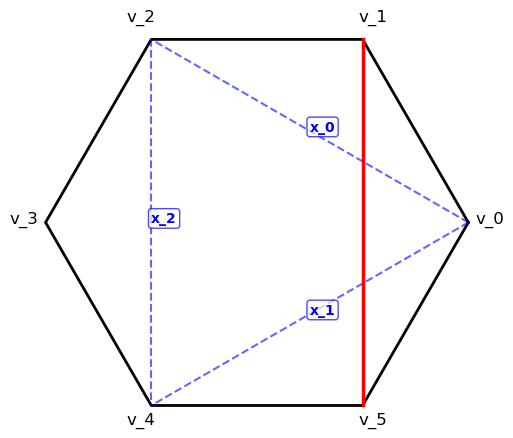

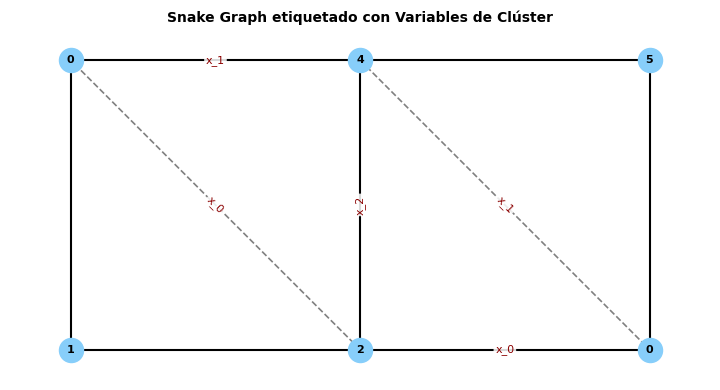

(x_0*y_0*y_1 + x_2*y_0 + x_1)/(x_0*x_1)


In [9]:
#Ejemplo 1
n=3
v=[[0,2],[0,4],[2,4]]
c=[1,5]
x_g= variable_cluster(n,v,c)
print(x_g)

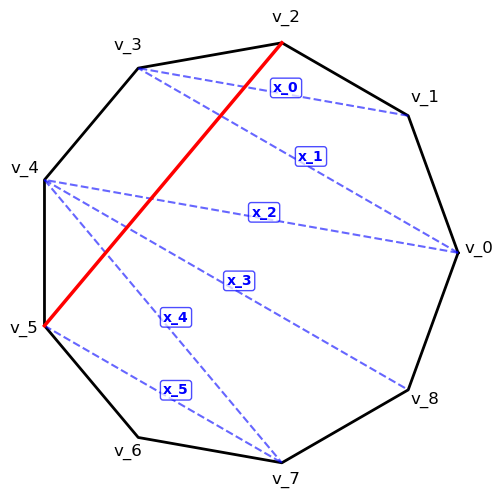

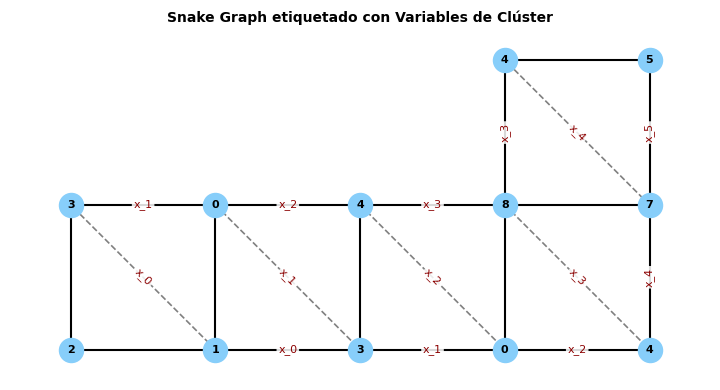

(x_0*x_2^2*x_3*x_5*y_0*y_1*y_2*y_3*y_4 + x_0*x_2^2*y_0*y_1*y_2*y_3 + x_1*x_2*x_3*x_5*y_2*y_3*y_4 + x_2*x_3*x_5*y_0*y_2*y_3*y_4 + x_0*x_2*x_4*y_0*y_1*y_2 + x_1^2*x_3*x_4 + x_1*x_3*x_4*y_0 + x_1*x_2*y_2*y_3 + x_2*y_0*y_2*y_3 + x_1*x_4*y_2 + x_4*y_0*y_2)/(x_0*x_1*x_2*x_3*x_4)


In [10]:
#Ejemplo 2
n=6
c=[2,5]
v=[[1,3],[0,3],[0,4],[4,8],[4,7], [5,7]]

x_g= variable_cluster(n,v,c)
print(x_g)

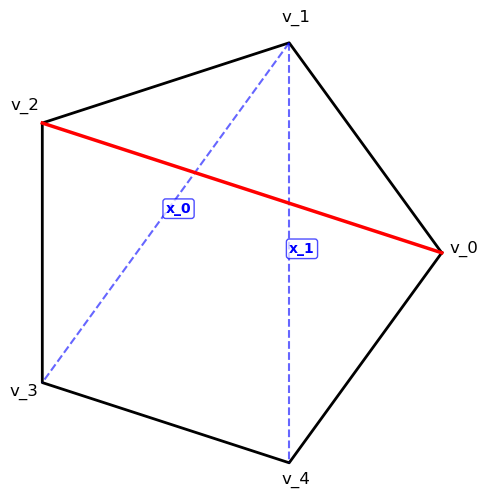

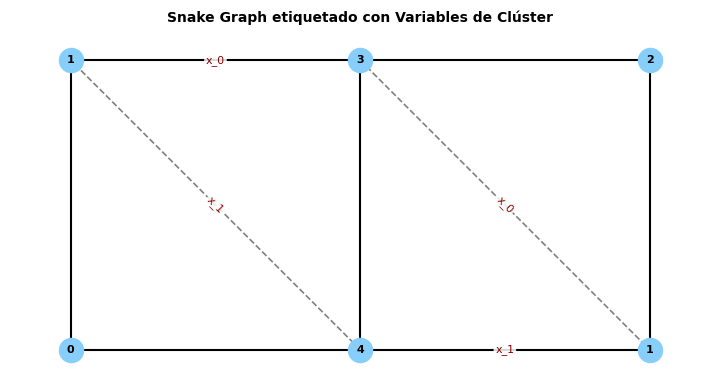

[0, 2] (x_1*y_0*y_1 + x_0 + y_0)/(x_0*x_1)


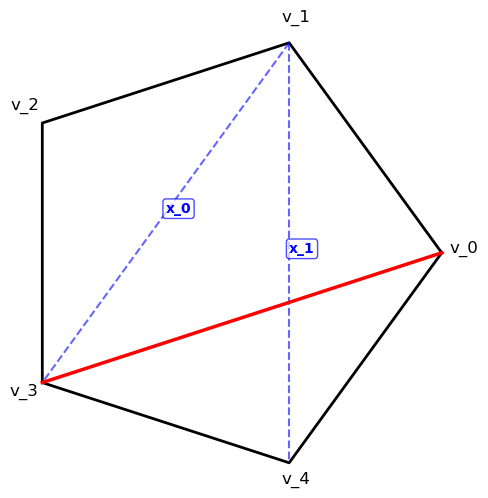

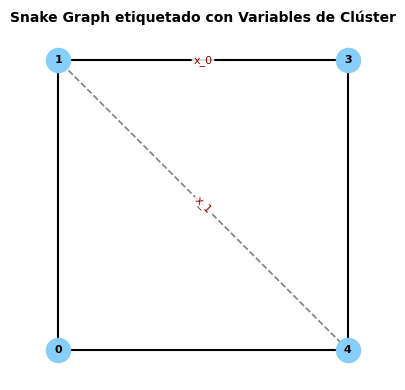

[0, 3] (x_0 + y_0)/x_1


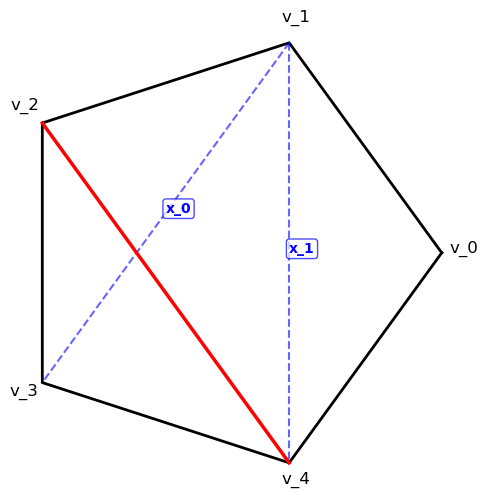

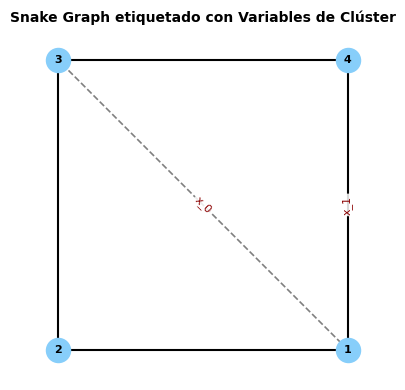

[2, 4] (x_1*y_0 + 1)/x_0


In [11]:
#Ejemplo 3
n=2
v=[[1,3],[1,4]]

for c in [[0,2],[0,3],[2,4]]:
    print(c, variable_cluster(n,v,c))

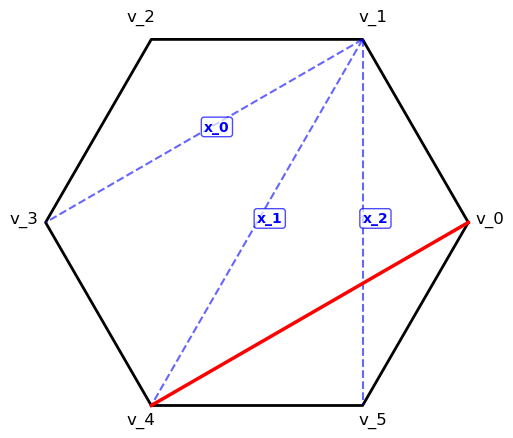

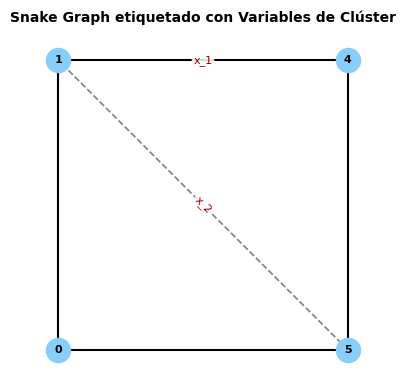

(x_1 + y_0)/x_2


In [12]:
#Más ejemplos 
n=3
c=[0,4]
v=[[1,3],[1,4],[1,5]]

x_g= variable_cluster(n,v,c)
print(x_g)

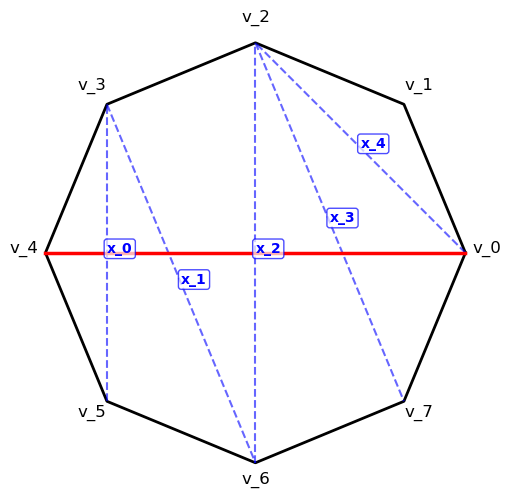

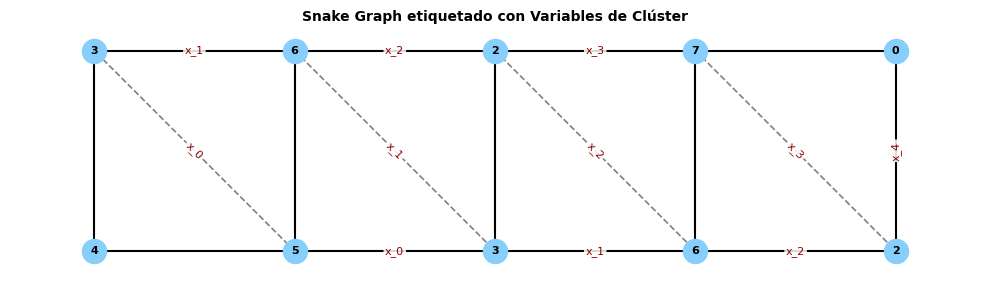

(x_0*x_2^2*y_0*y_1*y_2*y_3 + x_0*x_2*x_4*y_0*y_1*y_2 + x_1^2*x_3*x_4 + x_1*x_3*x_4*y_0 + x_1*x_2*y_2*y_3 + x_2*y_0*y_2*y_3 + x_1*x_4*y_2 + x_4*y_0*y_2)/(x_0*x_1*x_2*x_3)


In [13]:
n=5
c=[4,0]
v=[[5,3],[3,6],[6,2],[2,7],[0,2]]

x_g= variable_cluster(n,v,c)
print(x_g)